In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("ai4i2020.csv")

df.head()

,UDI,Product ID,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
0,1,M14860,M,298.1,308.6,1551,42.8,0,0,0,0,0,0,0
1,2,L47181,L,298.2,308.7,1408,46.3,3,0,0,0,0,0,0
2,3,L47182,L,298.1,308.5,1498,49.4,5,0,0,0,0,0,0
3,4,L47183,L,298.2,308.6,1433,39.5,7,0,0,0,0,0,0
4,5,L47184,L,298.2,308.7,1408,40.0,9,0,0,0,0,0,0


In [5]:
df.drop(columns=["TWF", "HDF", "PWF", "OSF", "RNF","Product ID"], inplace=True)

C:\Users\HP\AppData\Local\Temp\ipykernel_27264\750579211.py:1: Pandas4Warning: The inplace keyword in DataFrame.drop is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df.drop(columns=["TWF", "HDF", "PWF", "OSF", "RNF","Product ID"], inplace=True)


In [6]:
df.sample(10)

,UDI,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure
7598,7599,L,300.5,311.1,1491,42.6,11,0
3833,3834,M,302.3,311.0,1541,36.6,143,0
1506,1507,L,298.0,308.8,1610,33.7,212,0
1915,1916,L,298.0,307.7,1492,38.7,202,0
3204,3205,L,300.1,309.0,1404,54.8,29,0
3706,3707,L,302.0,311.3,1567,41.1,26,0
4420,4421,H,302.6,310.2,1873,21.3,87,0
5209,5210,M,303.8,312.7,1507,38.5,180,0
2861,2862,L,300.7,309.5,1479,43.6,240,0
1662,1663,H,298.2,307.9,1462,45.5,171,0


In [7]:
df.drop(columns=["UDI"])

,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure
0,M,298.1,308.6,1551,42.8,0,0
1,L,298.2,308.7,1408,46.3,3,0
2,L,298.1,308.5,1498,49.4,5,0
3,L,298.2,308.6,1433,39.5,7,0
4,L,298.2,308.7,1408,40.0,9,0
...,...,...,...,...,...,...,...
9995,M,298.8,308.4,1604,29.5,14,0
9996,H,298.9,308.4,1632,31.8,17,0
9997,M,299.0,308.6,1645,33.4,22,0
9998,H,299.0,308.7,1408,48.5,25,0


In [8]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 8 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   UDI                      10000 non-null  int64  
 1   Type                     10000 non-null  str    
 2   Air temperature [K]      10000 non-null  float64
 3   Process temperature [K]  10000 non-null  float64
 4   Rotational speed [rpm]   10000 non-null  int64  
 5   Torque [Nm]              10000 non-null  float64
 6   Tool wear [min]          10000 non-null  int64  
 7   Machine failure          10000 non-null  int64  
dtypes: float64(3), int64(4), str(1)
memory usage: 634.9 KB


In [10]:
df.describe()

,UDI,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure
count,10000.00000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000
mean,5000.50000,300.004930,310.005560,1538.776100,39.986910,107.951000,0.033900
std,2886.89568,2.000259,1.483734,179.284096,9.968934,63.654147,0.180981
min,1.00000,295.300000,305.700000,1168.000000,3.800000,0.000000,0.000000
25%,2500.75000,298.300000,308.800000,1423.000000,33.200000,53.000000,0.000000
50%,5000.50000,300.100000,310.100000,1503.000000,40.100000,108.000000,0.000000
75%,7500.25000,301.500000,311.100000,1612.000000,46.800000,162.000000,0.000000
max,10000.00000,304.500000,313.800000,2886.000000,76.600000,253.000000,1.000000


In [12]:
df["Machine failure"].value_counts()

Machine failure
0    9661
1     339
Name: count, dtype: int64

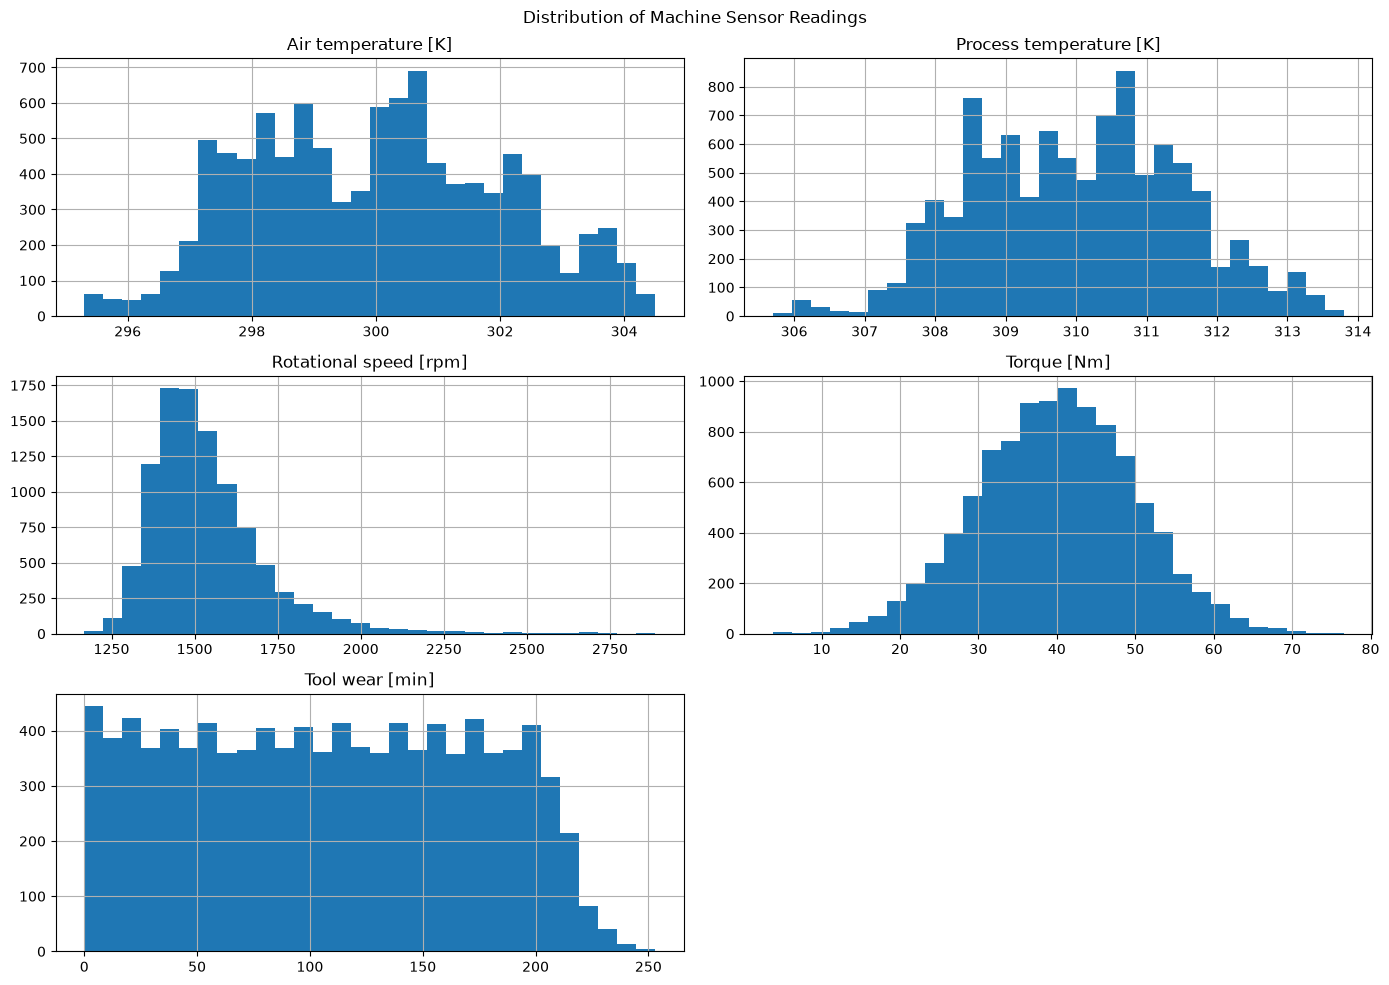

In [13]:
sensor_cols = [
    "Air temperature [K]",
    "Process temperature [K]",
    "Rotational speed [rpm]",
    "Torque [Nm]",
    "Tool wear [min]"
]

df[sensor_cols].hist(figsize=(14,10), bins=30)

plt.suptitle("Distribution of Machine Sensor Readings")
plt.tight_layout()
plt.show()

In [14]:
failure_by_type = df.groupby("Type")["Machine failure"].sum()

failure_by_type

Type
H     21
L    235
M     83
Name: Machine failure, dtype: int64

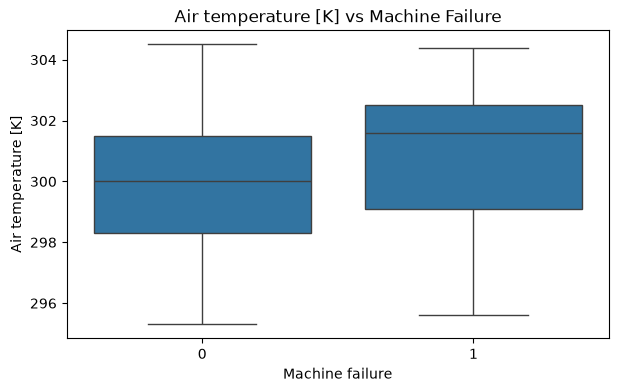

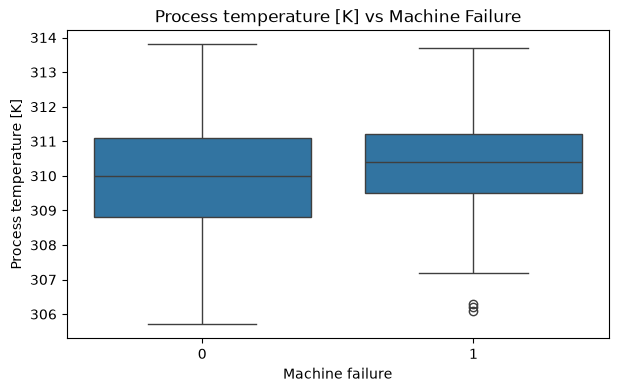

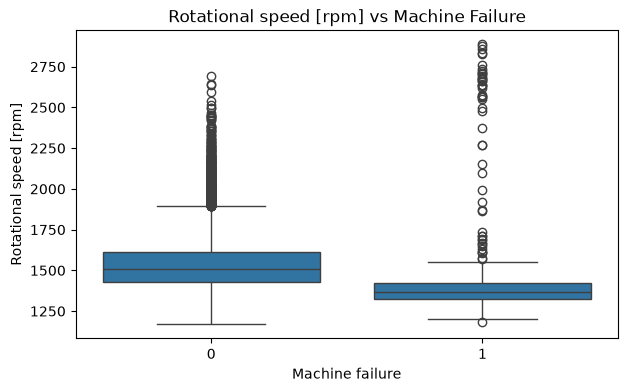

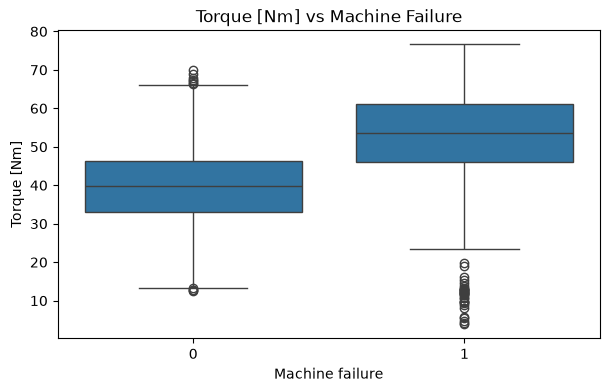

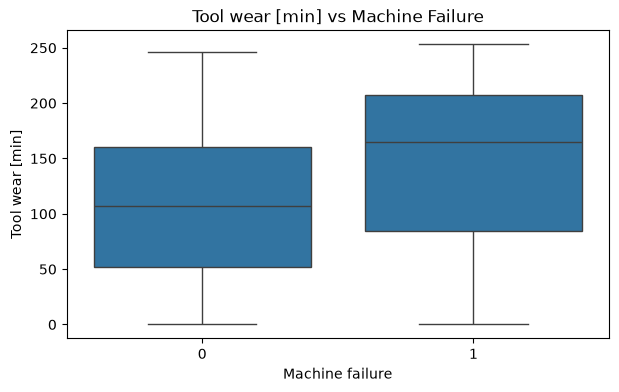

In [15]:
for col in sensor_cols:

    plt.figure(figsize=(7,4))

    sns.boxplot(
        data=df,
        x="Machine failure",
        y=col
    )

    plt.title(f"{col} vs Machine Failure")
    plt.show()

In [18]:
failure_rate = df.groupby("Type")["Machine failure"].mean() * 100

failure_rate

Type
H    2.093719
L    3.916667
M    2.769436
Name: Machine failure, dtype: float64

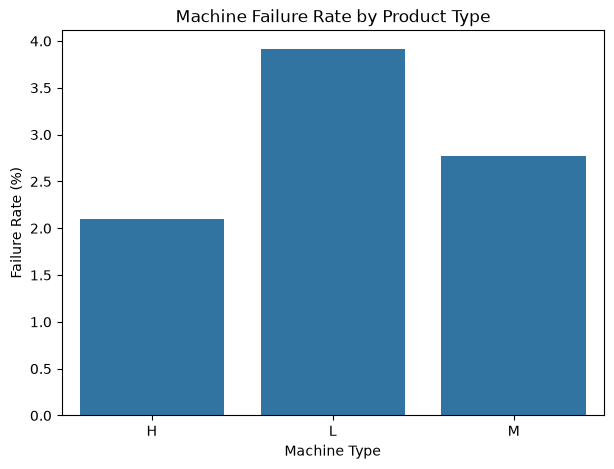

In [19]:
plt.figure(figsize=(7, 5))

sns.barplot(
    x=failure_rate.index,
    y=failure_rate.values
)

plt.title("Machine Failure Rate by Product Type")
plt.xlabel("Machine Type")
plt.ylabel("Failure Rate (%)")
plt.show()

In [20]:
# Create temperature difference
df["Temperature Difference"] = (
    df["Process temperature [K]"] - df["Air temperature [K]"]
)

# Calculate mechanical power in kW
df["Mechanical Power [kW]"] = (
    2 * np.pi * df["Rotational speed [rpm]"] *
    df["Torque [Nm]"] / (60 * 1000)
)

# Display the new features
df[[
    "Air temperature [K]",
    "Process temperature [K]",
    "Temperature Difference",
    "Rotational speed [rpm]",
    "Torque [Nm]",
    "Mechanical Power [kW]"
]].head()

,Air temperature [K],Process temperature [K],Temperature Difference,Rotational speed [rpm],Torque [Nm],Mechanical Power [kW]
0,298.1,308.6,10.5,1551,42.8,6.951591
1,298.2,308.7,10.5,1408,46.3,6.826723
2,298.1,308.5,10.4,1498,49.4,7.749388
3,298.2,308.6,10.4,1433,39.5,5.927505
4,298.2,308.7,10.5,1408,40.0,5.897817


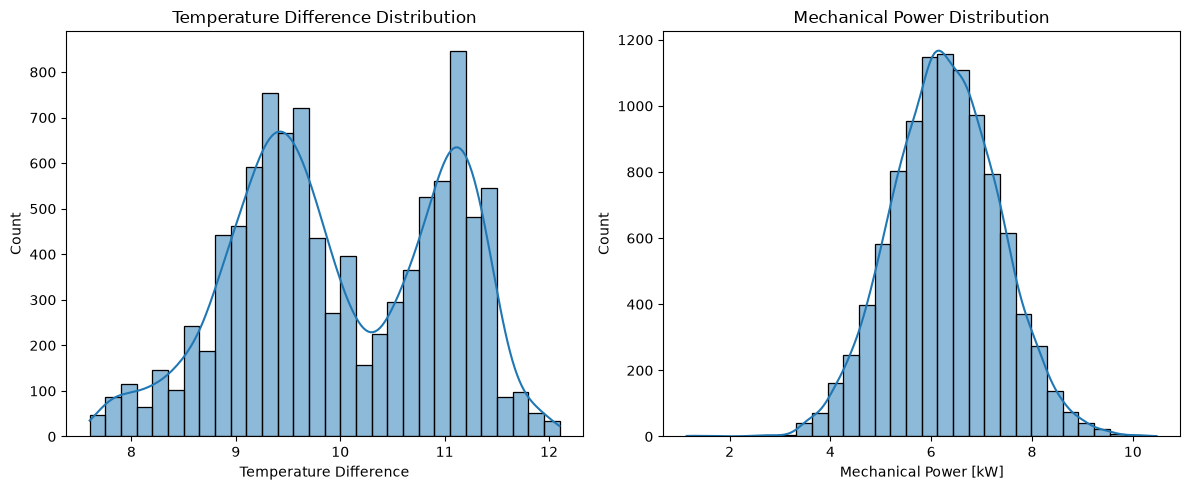

In [21]:
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
sns.histplot(df["Temperature Difference"], bins=30, kde=True)
plt.title("Temperature Difference Distribution")

plt.subplot(1, 2, 2)
sns.histplot(df["Mechanical Power [kW]"], bins=30, kde=True)
plt.title("Mechanical Power Distribution")

plt.tight_layout()
plt.show()

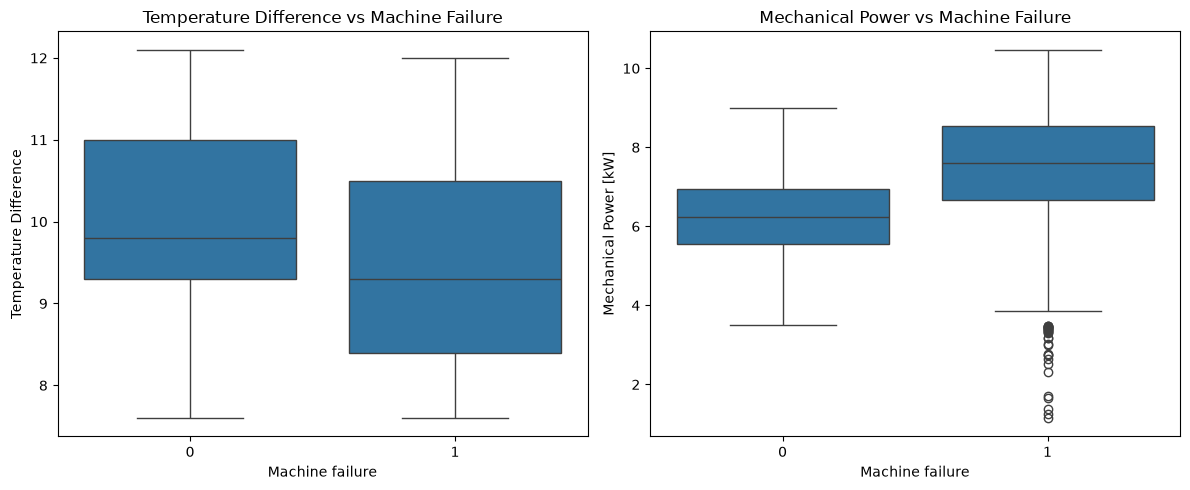

In [22]:
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
sns.boxplot(data=df, x="Machine failure",
            y="Temperature Difference")
plt.title("Temperature Difference vs Machine Failure")

plt.subplot(1, 2, 2)
sns.boxplot(data=df, x="Machine failure",
            y="Mechanical Power [kW]")
plt.title("Mechanical Power vs Machine Failure")

plt.tight_layout()
plt.show()

In [23]:
features = [
    "Type",
    "Air temperature [K]",
    "Process temperature [K]",
    "Rotational speed [rpm]",
    "Torque [Nm]",
    "Tool wear [min]",
    "Temperature Difference",
    "Mechanical Power [kW]"
]

X = df[features]
y = df["Machine failure"]

print("Features shape:", X.shape)
print("Target shape:", y.shape)

display(X.head())

Features shape: (10000, 8)
Target shape: (10000,)


,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Temperature Difference,Mechanical Power [kW]
0,M,298.1,308.6,1551,42.8,0,10.5,6.951591
1,L,298.2,308.7,1408,46.3,3,10.5,6.826723
2,L,298.1,308.5,1498,49.4,5,10.4,7.749388
3,L,298.2,308.6,1433,39.5,7,10.4,5.927505
4,L,298.2,308.7,1408,40.0,9,10.5,5.897817


In [24]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

print("\nTraining target distribution:")
print(y_train.value_counts())

print("\nTesting target distribution:")
print(y_test.value_counts())

Training data: (8000, 8)
Testing data: (2000, 8)

Training target distribution:
Machine failure
0    7729
1     271
Name: count, dtype: int64

Testing target distribution:
Machine failure
0    1932
1      68
Name: count, dtype: int64


In [25]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

categorical_features = ["Type"]

numerical_features = [
    "Air temperature [K]",
    "Process temperature [K]",
    "Rotational speed [rpm]",
    "Torque [Nm]",
    "Tool wear [min]",
    "Temperature Difference",
    "Mechanical Power [kW]"
]

preprocessor = ColumnTransformer(
    transformers=[
        ("cat", OneHotEncoder(drop="first", handle_unknown="ignore"),
         categorical_features),

        ("num", StandardScaler(), numerical_features)
    ]
)

X_train_processed = preprocessor.fit_transform(X_train)
X_test_processed = preprocessor.transform(X_test)

print("Processed training data:", X_train_processed.shape)
print("Processed testing data:", X_test_processed.shape)

Processed training data: (8000, 9)
Processed testing data: (2000, 9)


In [26]:
feature_names = preprocessor.get_feature_names_out()

print("Processed feature names:")
print(feature_names)

print("\nFirst 5 processed rows:")
display(pd.DataFrame(
    X_train_processed[:5],
    columns=feature_names
))

Processed feature names:
['cat__Type_L' 'cat__Type_M' 'num__Air temperature [K]'
 'num__Process temperature [K]' 'num__Rotational speed [rpm]'
 'num__Torque [Nm]' 'num__Tool wear [min]' 'num__Temperature Difference'
 'num__Mechanical Power [kW]']

First 5 processed rows:


,cat__Type_L,cat__Type_M,num__Air temperature [K],num__Process temperature [K],num__Rotational speed [rpm],num__Torque [Nm],num__Tool wear [min],num__Temperature Difference,num__Mechanical Power [kW]
0,0.0,1.0,0.998914,0.604282,-0.460607,0.718305,-0.843997,-1.100842,0.852387
1,0.0,1.0,-1.505194,-1.153260,-0.775574,0.638456,0.382263,1.299658,0.480363
2,0.0,1.0,0.498092,1.077466,-1.007654,0.558607,0.460870,0.599512,0.184041
3,1.0,0.0,-0.553633,-0.139294,-0.709265,1.626586,-0.372359,0.899575,1.898861
4,1.0,0.0,-1.455112,-1.018064,1.070019,-1.128202,-0.906882,1.399679,-1.001687


In [36]:
from sklearn.linear_model import LogisticRegression

# Create the model
model = LogisticRegression(
    max_iter=111,
    class_weight="balanced",
    random_state=42
)

# Train the model
model.fit(X_train_processed, y_train)

print("Model training completed successfully!")

Model training completed successfully!


In [37]:
y_pred = model.predict(X_test_processed)

print("First 20 actual values:")
print(y_test.values[:20])

print("\nFirst 20 predicted values:")
print(y_pred[:20])

First 20 actual values:
[0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 1 0 0]

First 20 predicted values:
[1 0 1 0 1 1 1 0 0 1 0 0 0 0 0 0 0 1 0 0]


In [38]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

print("Accuracy:", accuracy_score(y_test, y_pred))
print("Precision:", precision_score(y_test, y_pred))
print("Recall:", recall_score(y_test, y_pred))
print("F1 Score:", f1_score(y_test, y_pred))

print("\nDetailed Classification Report:")
print(classification_report(y_test, y_pred))

Accuracy: 0.859
Precision: 0.17771084337349397
Recall: 0.8676470588235294
F1 Score: 0.295

Detailed Classification Report:
              precision    recall  f1-score   support

           0       0.99      0.86      0.92      1932
           1       0.18      0.87      0.29        68

    accuracy                           0.86      2000
   macro avg       0.59      0.86      0.61      2000
weighted avg       0.97      0.86      0.90      2000



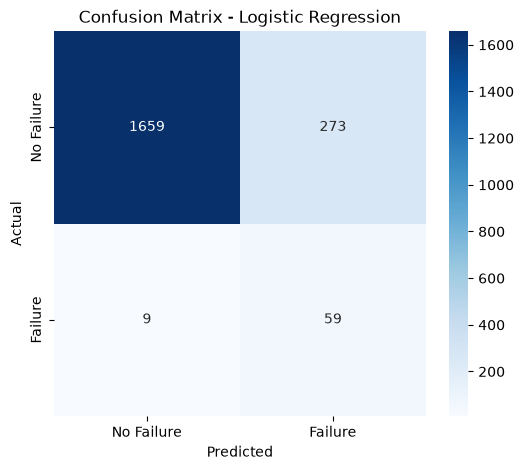

In [39]:
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(6, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["No Failure", "Failure"],
    yticklabels=["No Failure", "Failure"]
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix - Logistic Regression")

plt.show()

In [31]:
y_probability = model.predict_proba(X_test_processed)[:, 1]

results = pd.DataFrame({
    "Actual Failure": y_test.values,
    "Predicted Failure": y_pred,
    "Failure Probability": y_probability
})

display(results.head(10))

,Actual Failure,Predicted Failure,Failure Probability
0,0,1,0.968243
1,0,0,0.362542
2,0,1,0.504537
3,0,0,0.013291
4,0,1,0.838337
5,0,1,0.597694
6,0,1,0.692179
7,0,0,0.066635
8,0,0,0.019046
9,0,1,0.618137


In [40]:
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test, y_pred)

print("True Negatives:", cm[0, 0])
print("False Positives:", cm[0, 1])
print("False Negatives:", cm[1, 0])
print("True Positives:", cm[1, 1])

True Negatives: 1659
False Positives: 273
False Negatives: 9
True Positives: 59


In [41]:
from sklearn.metrics import precision_score, recall_score, f1_score

thresholds = [0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8]

threshold_results = []

for threshold in thresholds:

    predictions = (y_probability >= threshold).astype(int)

    threshold_results.append({
        "Threshold": threshold,
        "Precision": precision_score(y_test, predictions, zero_division=0),
        "Recall": recall_score(y_test, predictions),
        "F1 Score": f1_score(y_test, predictions)
    })

threshold_df = pd.DataFrame(threshold_results)

display(threshold_df.round(3))

,Threshold,Precision,Recall,F1 Score
0,0.2,0.083,0.971,0.152
1,0.3,0.106,0.912,0.190
2,0.4,0.139,0.912,0.241
3,0.5,0.178,0.868,0.295
4,0.6,0.224,0.809,0.350
5,0.7,0.276,0.779,0.408
6,0.8,0.397,0.676,0.500


In [42]:
thresholds = np.arange(0.50, 0.86, 0.05)

results = []

for t in thresholds:
    pred = (y_probability >= t).astype(int)

    results.append({
        "Threshold": round(t, 2),
        "Precision": precision_score(y_test, pred, zero_division=0),
        "Recall": recall_score(y_test, pred),
        "F1 Score": f1_score(y_test, pred)
    })

fine_tuning_df = pd.DataFrame(results)

display(fine_tuning_df.round(3))

,Threshold,Precision,Recall,F1 Score
0,0.50,0.178,0.868,0.295
1,0.55,0.198,0.824,0.319
2,0.60,0.224,0.809,0.350
3,0.65,0.251,0.794,0.382
4,0.70,0.276,0.779,0.408
5,0.75,0.327,0.750,0.455
6,0.80,0.397,0.676,0.500
7,0.85,0.440,0.588,0.503


In [43]:
# Set our chosen threshold
THRESHOLD = 0.65

# Generate predictions using the fixed threshold
lr_probability = model.predict_proba(X_test_processed)[:, 1]

lr_final_pred = (lr_probability >= THRESHOLD).astype(int)

print("Threshold:", THRESHOLD)

Threshold: 0.65


In [44]:
print("Logistic Regression - Threshold 0.65")

print("Accuracy:", accuracy_score(y_test, lr_final_pred))
print("Precision:", precision_score(y_test, lr_final_pred))
print("Recall:", recall_score(y_test, lr_final_pred))
print("F1 Score:", f1_score(y_test, lr_final_pred))

print("\nClassification Report:")
print(classification_report(y_test, lr_final_pred))

Logistic Regression - Threshold 0.65
Accuracy: 0.9125
Precision: 0.25116279069767444
Recall: 0.7941176470588235
F1 Score: 0.38162544169611307

Classification Report:
              precision    recall  f1-score   support

           0       0.99      0.92      0.95      1932
           1       0.25      0.79      0.38        68

    accuracy                           0.91      2000
   macro avg       0.62      0.86      0.67      2000
weighted avg       0.97      0.91      0.93      2000



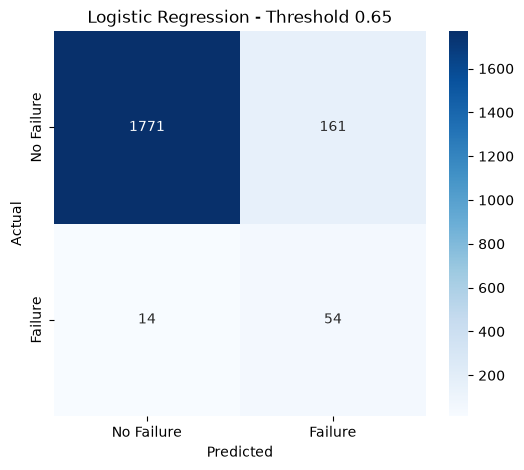

In [45]:
cm = confusion_matrix(y_test, lr_final_pred)

plt.figure(figsize=(6, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["No Failure", "Failure"],
    yticklabels=["No Failure", "Failure"]
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Logistic Regression - Threshold 0.65")

plt.show()

In [46]:
from sklearn.ensemble import RandomForestClassifier

In [47]:
rf_model = RandomForestClassifier(
    n_estimators=200,
    max_depth=None,
    min_samples_split=2,
    min_samples_leaf=1,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)

# Train the model
rf_model.fit(X_train_processed, y_train)

print("Random Forest training completed!")

Random Forest training completed!


In [48]:
# Predict machine failures
rf_pred = rf_model.predict(X_test_processed)

# Get probability of machine failure
rf_probability = rf_model.predict_proba(X_test_processed)[:, 1]

print("First 20 predictions:")
print(rf_pred[:20])

First 20 predictions:
[0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 1 0 0]


In [49]:
print("RANDOM FOREST PERFORMANCE")

print("Accuracy:", accuracy_score(y_test, rf_pred))
print("Precision:", precision_score(y_test, rf_pred))
print("Recall:", recall_score(y_test, rf_pred))
print("F1 Score:", f1_score(y_test, rf_pred))

print("\nClassification Report:")
print(classification_report(y_test, rf_pred))

RANDOM FOREST PERFORMANCE
Accuracy: 0.991
Precision: 0.9166666666666666
Recall: 0.8088235294117647
F1 Score: 0.859375

Classification Report:
              precision    recall  f1-score   support

           0       0.99      1.00      1.00      1932
           1       0.92      0.81      0.86        68

    accuracy                           0.99      2000
   macro avg       0.95      0.90      0.93      2000
weighted avg       0.99      0.99      0.99      2000



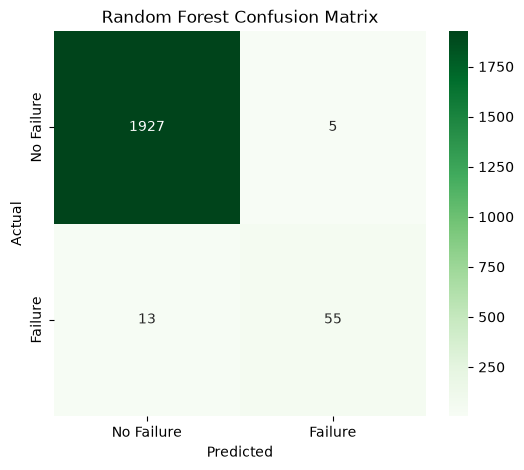

In [50]:
rf_cm = confusion_matrix(y_test, rf_pred)

plt.figure(figsize=(6, 5))

sns.heatmap(
    rf_cm,
    annot=True,
    fmt="d",
    cmap="Greens",
    xticklabels=["No Failure", "Failure"],
    yticklabels=["No Failure", "Failure"]
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Random Forest Confusion Matrix")

plt.show()

In [51]:
comparison = pd.DataFrame({
    "Model": ["Logistic Regression", "Random Forest"],

    "Accuracy": [
        accuracy_score(y_test, lr_final_pred),
        accuracy_score(y_test, rf_pred)
    ],

    "Precision": [
        precision_score(y_test, lr_final_pred),
        precision_score(y_test, rf_pred)
    ],

    "Recall": [
        recall_score(y_test, lr_final_pred),
        recall_score(y_test, rf_pred)
    ],

    "F1 Score": [
        f1_score(y_test, lr_final_pred),
        f1_score(y_test, rf_pred)
    ]
})

display(comparison.round(3))

,Model,Accuracy,Precision,Recall,F1 Score
0,Logistic Regression,0.912,0.251,0.794,0.382
1,Random Forest,0.991,0.917,0.809,0.859


In [52]:
# Logistic Regression probability
lr_probability = model.predict_proba(X_test_processed)[:, 1]

# Apply threshold 0.5
lr_pred_05 = (lr_probability >= 0.5).astype(int)

In [53]:
comparison_05 = pd.DataFrame({
    "Model": ["Logistic Regression", "Random Forest"],

    "Threshold": [0.5, 0.5],

    "Accuracy": [
        accuracy_score(y_test, lr_pred_05),
        accuracy_score(y_test, rf_pred)
    ],

    "Precision": [
        precision_score(y_test, lr_pred_05),
        precision_score(y_test, rf_pred)
    ],

    "Recall": [
        recall_score(y_test, lr_pred_05),
        recall_score(y_test, rf_pred)
    ],

    "F1 Score": [
        f1_score(y_test, lr_pred_05),
        f1_score(y_test, rf_pred)
    ]
})

display(comparison_05.round(3))

,Model,Threshold,Accuracy,Precision,Recall,F1 Score
0,Logistic Regression,0.5,0.859,0.178,0.868,0.295
1,Random Forest,0.5,0.991,0.917,0.809,0.859


In [54]:
from sklearn.metrics import accuracy_score

# Training predictions
rf_train_pred = rf_model.predict(X_train_processed)

# Testing predictions
rf_test_pred = rf_model.predict(X_test_processed)

# Compare accuracy
print("Training Accuracy:",
      accuracy_score(y_train, rf_train_pred))

print("Testing Accuracy:",
      accuracy_score(y_test, rf_test_pred))

Training Accuracy: 1.0
Testing Accuracy: 0.991


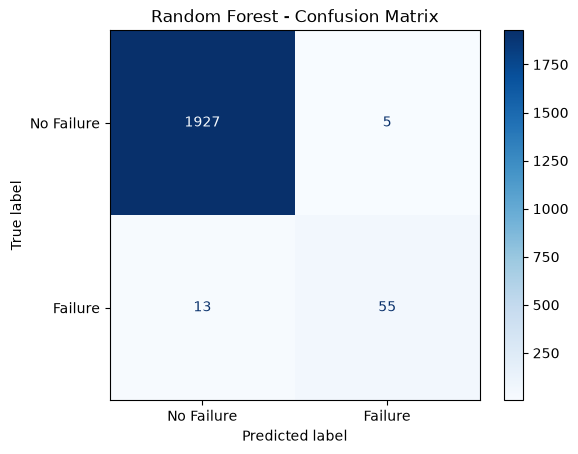

[[1927    5]
 [  13   55]]


In [55]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

cm = confusion_matrix(y_test, rf_pred)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["No Failure", "Failure"]
)

disp.plot(cmap="Blues")
plt.title("Random Forest - Confusion Matrix")
plt.show()

print(cm)

In [56]:
from sklearn.metrics import precision_score, recall_score, f1_score

thresholds = [0.5, 0.4, 0.3, 0.2, 0.1]

results = []

for threshold in thresholds:

    # Convert probabilities into predictions
    predictions = (rf_probability >= threshold).astype(int)

    results.append({
        "Threshold": threshold,
        "Precision": precision_score(y_test, predictions, zero_division=0),
        "Recall": recall_score(y_test, predictions, zero_division=0),
        "F1 Score": f1_score(y_test, predictions, zero_division=0)
    })

threshold_results = pd.DataFrame(results)

display(threshold_results.round(3))

,Threshold,Precision,Recall,F1 Score
0,0.5,0.917,0.809,0.859
1,0.4,0.800,0.824,0.812
2,0.3,0.617,0.853,0.716
3,0.2,0.484,0.897,0.629
4,0.1,0.328,0.926,0.485


In [57]:
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import precision_score, recall_score, f1_score

# Split training data into training and validation
X_subtrain, X_val, y_subtrain, y_val = train_test_split(
    X_train_processed,
    y_train,
    test_size=0.2,
    random_state=42,
    stratify=y_train
)

# Train a fresh Random Forest model
rf_validation_model = RandomForestClassifier(
    n_estimators=200,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)

rf_validation_model.fit(X_subtrain, y_subtrain)

# Get failure probabilities on validation data
val_probability = rf_validation_model.predict_proba(X_val)[:, 1]

In [58]:
thresholds = [0.5, 0.4, 0.3, 0.2, 0.1]

validation_results = []

for threshold in thresholds:

    val_pred = (val_probability >= threshold).astype(int)

    validation_results.append({
        "Threshold": threshold,
        "Precision": precision_score(y_val, val_pred),
        "Recall": recall_score(y_val, val_pred),
        "F1 Score": f1_score(y_val, val_pred)
    })

validation_table = pd.DataFrame(validation_results)

display(validation_table.round(3))

,Threshold,Precision,Recall,F1 Score
0,0.5,0.872,0.759,0.812
1,0.4,0.840,0.778,0.808
2,0.3,0.652,0.796,0.717
3,0.2,0.511,0.833,0.634
4,0.1,0.303,0.926,0.457


In [59]:
thresholds = np.arange(0.10, 0.51, 0.02)

fine_results = []

for threshold in thresholds:

    val_pred = (val_probability >= threshold).astype(int)

    fine_results.append({
        "Threshold": round(threshold, 2),
        "Precision": precision_score(y_val, val_pred, zero_division=0),
        "Recall": recall_score(y_val, val_pred, zero_division=0),
        "F1 Score": f1_score(y_val, val_pred, zero_division=0)
    })

fine_table = pd.DataFrame(fine_results)

display(fine_table.round(3))

,Threshold,Precision,Recall,F1 Score
0,0.10,0.303,0.926,0.457
1,0.12,0.350,0.889,0.503
2,0.14,0.390,0.889,0.542
3,0.16,0.435,0.870,0.580
4,0.18,0.484,0.833,0.612
5,0.20,0.511,0.833,0.634
6,0.22,0.543,0.815,0.652
7,0.24,0.557,0.815,0.662
8,0.26,0.589,0.796,0.677
9,0.28,0.632,0.796,0.705


In [60]:
# Predict probabilities on test data
rf_test_probability = rf_model.predict_proba(X_test_processed)[:, 1]

# Apply selected threshold
FINAL_THRESHOLD = 0.2

rf_final_pred = (
    rf_test_probability >= FINAL_THRESHOLD
).astype(int)

Classification Report:
              precision    recall  f1-score   support

  No Failure       1.00      0.97      0.98      1932
     Failure       0.48      0.90      0.63        68

    accuracy                           0.96      2000
   macro avg       0.74      0.93      0.80      2000
weighted avg       0.98      0.96      0.97      2000



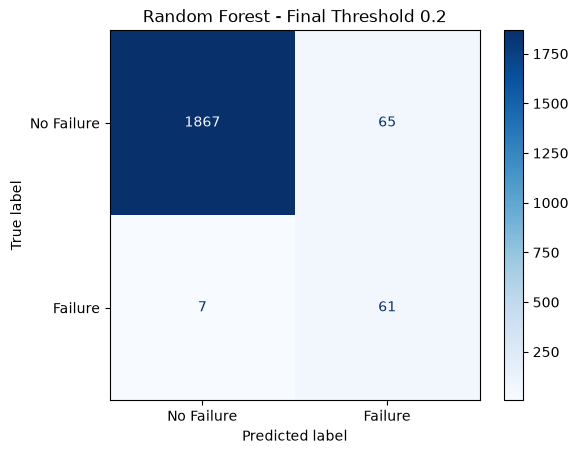

In [61]:
from sklearn.metrics import classification_report, confusion_matrix

print("Classification Report:")
print(classification_report(
    y_test,
    rf_final_pred,
    target_names=["No Failure", "Failure"]
))

cm = confusion_matrix(y_test, rf_final_pred)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["No Failure", "Failure"]
)

disp.plot(cmap="Blues")
plt.title("Random Forest - Final Threshold 0.2")
plt.show()

In [62]:
# Extract feature importance from Random Forest
importance = rf_model.feature_importances_

# Create a DataFrame
feature_importance = pd.DataFrame({
    "Feature": feature_names,
    "Importance": importance
})

# Sort from highest to lowest
feature_importance = feature_importance.sort_values(
    by="Importance",
    ascending=False
)

display(feature_importance.round(4))

,Feature,Importance
6,num__Tool wear [min],0.2198
4,num__Rotational speed [rpm],0.2144
8,num__Mechanical Power [kW],0.1971
5,num__Torque [Nm],0.1912
7,num__Temperature Difference,0.0901
2,num__Air temperature [K],0.0451
3,num__Process temperature [K],0.0300
0,cat__Type_L,0.0075
1,cat__Type_M,0.0047


In [63]:
from sklearn.inspection import permutation_importance
from sklearn.metrics import recall_score

# Custom scoring function using our selected threshold
def recall_at_threshold(estimator, X, y):
    probabilities = estimator.predict_proba(X)[:, 1]
    predictions = (probabilities >= 0.2).astype(int)

    return recall_score(y, predictions)

# Calculate permutation importance on validation data
perm_result = permutation_importance(
    rf_validation_model,
    X_val,
    y_val,
    scoring=recall_at_threshold,
    n_repeats=10,
    random_state=42,
    n_jobs=-1
)

# Create results table
permutation_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": perm_result.importances_mean,
    "Std": perm_result.importances_std
})

permutation_df = permutation_df.sort_values(
    by="Importance",
    ascending=False
)

display(permutation_df.round(4))

,Feature,Importance,Std
8,num__Mechanical Power [kW],0.2741,0.0231
6,num__Tool wear [min],0.1870,0.0175
4,num__Rotational speed [rpm],0.1167,0.0235
7,num__Temperature Difference,0.1056,0.0220
5,num__Torque [Nm],0.1000,0.0372
2,num__Air temperature [K],0.0037,0.0111
0,cat__Type_L,0.0000,0.0000
1,cat__Type_M,0.0000,0.0000
3,num__Process temperature [K],-0.0241,0.0085


In [64]:
from sklearn.inspection import PartialDependenceDisplay

important_features = [
    "num__Mechanical Power [kW]",
    "num__Tool wear [min]",
    "num__Rotational speed [rpm]",
    "num__Torque [Nm]"
]

PartialDependenceDisplay.from_estimator(
    rf_model,
    X_train_processed,
    features=important_features,
    kind="average",
    response_method="predict_proba",
    n_jobs=-1
)

plt.suptitle(
    "Partial Dependence Plots - Machine Failure",
    y=1.02
)

plt.tight_layout()
plt.show()


ValueError: Feature 'num__Mechanical Power [kW]' not in feature_names

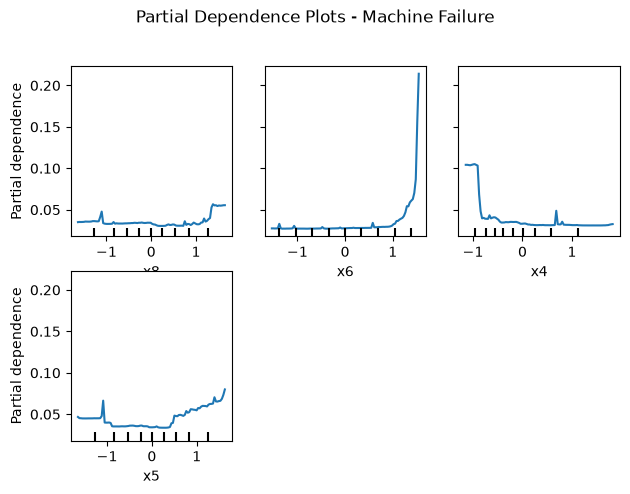

In [65]:
from sklearn.inspection import PartialDependenceDisplay

important_features = [8, 6, 4, 5]

PartialDependenceDisplay.from_estimator(
    rf_model,
    X_train_processed,
    features=important_features,
    kind="average",
    response_method="predict_proba",
    n_jobs=-1
)

plt.suptitle(
    "Partial Dependence Plots - Machine Failure",
    y=1.02
)

plt.tight_layout()
plt.show()

In [66]:
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestClassifier

# Combine preprocessing and Random Forest
final_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", RandomForestClassifier(
        n_estimators=200,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    ))
])

# Train using original, unscaled features
final_pipeline.fit(X_train, y_train)

print("Pipeline trained successfully!")

Pipeline trained successfully!


In [67]:
from sklearn.inspection import PartialDependenceDisplay

important_features = [
    "Mechanical Power [kW]",
    "Tool wear [min]",
    "Rotational speed [rpm]",
    "Torque [Nm]"
]

PartialDependenceDisplay.from_estimator(
    final_pipeline,
    X_train,
    features=important_features,
    kind="average",
    response_method="predict_proba",
    n_jobs=-1
)

plt.suptitle(
    "Machine Failure - Sensor Feature Analysis",
    y=1.02
)

plt.tight_layout()
plt.show()

ValueError: The column 5 contains integer data. Partial dependence plots are not supported for integer data: this can lead to implicit rounding with NumPy arrays or even errors with newer pandas versions. Please convert numerical features to floating point dtypes ahead of time to avoid problems.

In [68]:
# Create copies of training and testing data
X_train_float = X_train.copy()
X_test_float = X_test.copy()

# Convert all numerical features to float
for col in numerical_features:
    X_train_float[col] = X_train_float[col].astype(float)
    X_test_float[col] = X_test_float[col].astype(float)

print(X_train_float.dtypes)

Type                           str
Air temperature [K]        float64
Process temperature [K]    float64
Rotational speed [rpm]     float64
Torque [Nm]                float64
Tool wear [min]            float64
Temperature Difference     float64
Mechanical Power [kW]      float64
dtype: object


In [69]:
final_pipeline.fit(X_train_float, y_train)

print("Pipeline trained successfully!")

Pipeline trained successfully!


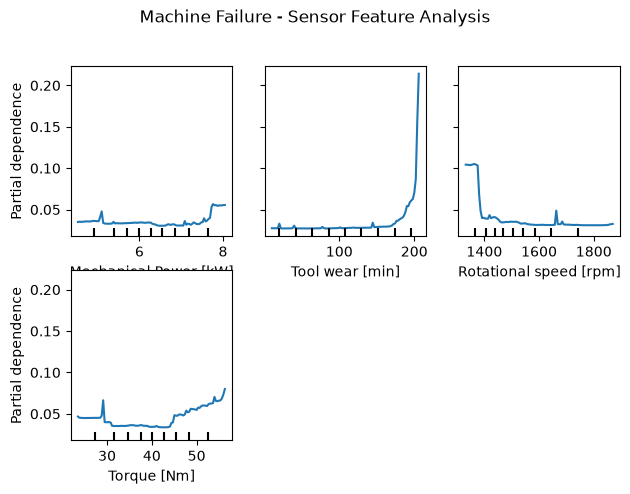

In [70]:
important_features = [
    "Mechanical Power [kW]",
    "Tool wear [min]",
    "Rotational speed [rpm]",
    "Torque [Nm]"
]

PartialDependenceDisplay.from_estimator(
    final_pipeline,
    X_train_float,
    features=important_features,
    kind="average",
    response_method="predict_proba",
    n_jobs=-1
)

plt.suptitle(
    "Machine Failure - Sensor Feature Analysis",
    y=1.02
)

plt.tight_layout()
plt.show()

In [71]:
import joblib

joblib.dump(
    final_pipeline,
    "machine_failure_model.pkl"
)

print("Model saved successfully!")

Model saved successfully!


In [72]:
joblib.dump(
    0.2,
    "failure_threshold.pkl"
)

print("Threshold saved successfully!")

Threshold saved successfully!


In [73]:
import os

print(os.listdir())

['ai4i2020.csv', 'failure_threshold.pkl', 'first.py', 'machine_failure_analysis.ipynb', 'machine_failure_model.pkl', 'requirements.txt']
